# 02 First EDA: Who is financially excluded?

This notebook uses the cleaned Global Findex 2025 microdata to identify which groups have lower account ownership.

Main question:

> Who is financially excluded?


## Setup

The cleaned dataset is generated by:

```bash
python -m src.clean_microdata
```


In [4]:
import pandas as pd
import sys
from pathlib import Path

project_root = Path.cwd().resolve()
if not (project_root / "src").exists():
	for parent in project_root.parents:
		if (parent / "src").exists():
			project_root = parent
			break

if str(project_root) not in sys.path:
	sys.path.insert(0, str(project_root))

from src.config import INTERIM_DIR, FIGURES_DIR
from src.eda import account_summary, add_age_group, add_readable_flags, grouped_weighted_rate


In [5]:
df=pd.read_parquet(INTERIM_DIR / 'microdata_core.parquet')
df=add_readable_flags(add_age_group(df))
df.shape

(144090, 21)

## Overall account ownership

Account ownership is the main definition of basic financial inclusion in this project.


In [6]:
account_summary(df)

rows                       144090.000000
weighted_account_rate           0.710492
unweighted_account_rate         0.737817
excluded_rows               37778.000000
included_rows              106312.000000
dtype: float64

Initial finding:

- Weighted account ownership is about 71%.
- About 37,778 respondents in the sample do not own an account.
- This means the project has a meaningful excluded group to analyze.


## Demographic gaps

We compare weighted account ownership across demographic groups.


In [7]:
grouped_weighted_rate(df, 'gender')

,gender,n,weighted_n,has_account_rate
1,women,75580,73277.599161,0.680541
0,men,68510,70812.401151,0.741485


In [8]:
grouped_weighted_rate(df, 'education_level')

,education_level,n,weighted_n,has_account_rate
0,primary_or_less,38398,50373.457738,0.518771
3,<NA>,588,671.733715,0.645418
1,secondary,74624,70657.383078,0.776959
2,tertiary_or_more,30480,22387.425781,0.934055


In [9]:
grouped_weighted_rate(df, 'income_quintile')

,income_quintile,n,weighted_n,has_account_rate
0,1,23851,28525.233542,0.611417
5,<NA>,1020,1020.000000,0.615710
1,2,25615,28592.343385,0.670760
2,3,27916,28600.989584,0.715551
3,4,30139,28631.547951,0.751627
4,5,35549,28719.885850,0.805769


Initial finding:

- Account ownership is lower among women than men.
- Education shows one of the strongest gradients: adults with primary education or less have much lower account ownership than adults with tertiary education.
- Account ownership rises steadily across income quintiles.


## Digital access and geography


In [10]:
grouped_weighted_rate(df, 'internet_status')

,internet_status,n,weighted_n,has_account_rate
0,does_not_use_internet,35529,38366.715273,0.464882
1,uses_internet,108561,105723.285039,0.799623


In [11]:
grouped_weighted_rate(df, 'urbanicity')

,urbanicity,n,weighted_n,has_account_rate
0,rural,79534,80361.944848,0.662851
1,urban,62030,61083.791012,0.766097
2,<NA>,2526,2644.264452,0.873856


In [12]:
grouped_weighted_rate(df, 'region')

,region,n,weighted_n,has_account_rate
4,Middle East & North Africa (excluding high inc...,10046,10046.000000,0.424295
6,Sub-Saharan Africa (excluding high income),35093,35093.000000,0.556169
3,Latin America & Caribbean (excluding high income),15696,15696.000000,0.593482
5,South Asia,7000,7000.000000,0.684768
1,Europe & Central Asia (excluding high income),18000,18000.000000,0.721861
0,East Asia & Pacific (excluding high income),12088,12088.000000,0.740973
2,High income,46167,46167.000312,0.921342


Initial finding:

- Internet use is strongly associated with account ownership.
- Rural respondents have lower account ownership than urban respondents.
- Regional gaps are large, especially between high-income economies and lower-inclusion regions.


## Country ranking


In [13]:
country=grouped_weighted_rate(df, 'economy', min_n=300)
country.head(15)

,economy,n,weighted_n,has_account_rate
95,Niger,1000,1000.0,0.148269
21,Chad,1000,1000.0,0.208984
72,Lebanon,1010,1010.0,0.230439
94,Nicaragua,1130,1130.0,0.234706
77,Madagascar,1000,1000.0,0.244501
100,Pakistan,1000,1000.0,0.272960
82,Mauritania,1000,1000.0,0.273143
58,Iraq,1000,1000.0,0.301611
75,Libya,1000,1000.0,0.331191
1,Algeria,1007,1007.0,0.352901


In [14]:
country.tail(15).sort_values('has_account_rate', ascending=False)

,economy,n,weighted_n,has_account_rate
54,Iceland,500,500.0,0.998548
41,Finland,1000,1000.0,0.998427
5,Austria,1000,1000.0,0.995085
131,United Kingdom,1000,1000.0,0.992843
42,France,1000,1000.0,0.991902
92,Netherlands,1004,1004.0,0.991715
76,Lithuania,1012,1012.0,0.989947
38,Estonia,1006,1006.0,0.989011
115,Slovenia,1001,1001.0,0.987473
33,Denmark,1005,1005.0,0.986505


Initial finding:

- The lowest-account-ownership countries include Niger, Chad, Lebanon, Nicaragua, Madagascar, Pakistan, and Mauritania.
- High-income countries dominate the highest-account-ownership group.


## Figures

The project also saves first-pass EDA figures using:

```bash
python -m src.make_first_eda_figures
```


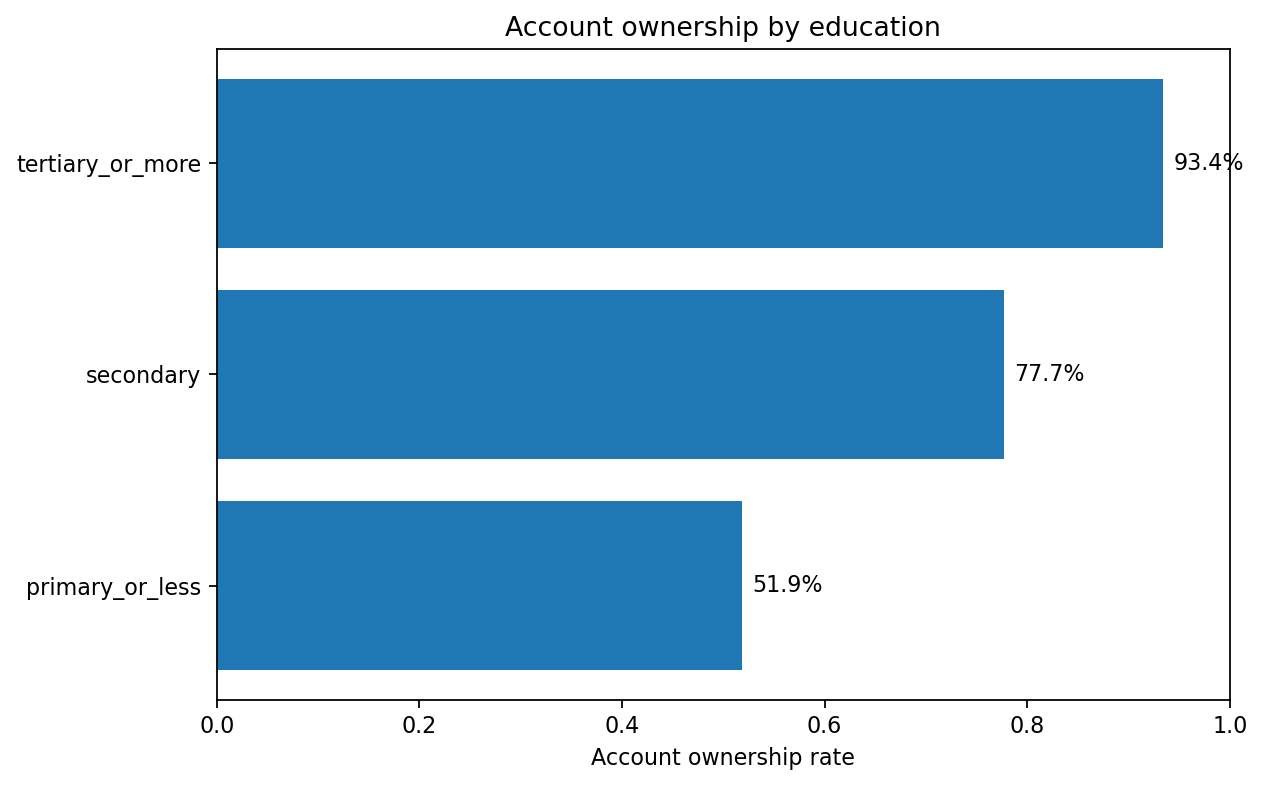

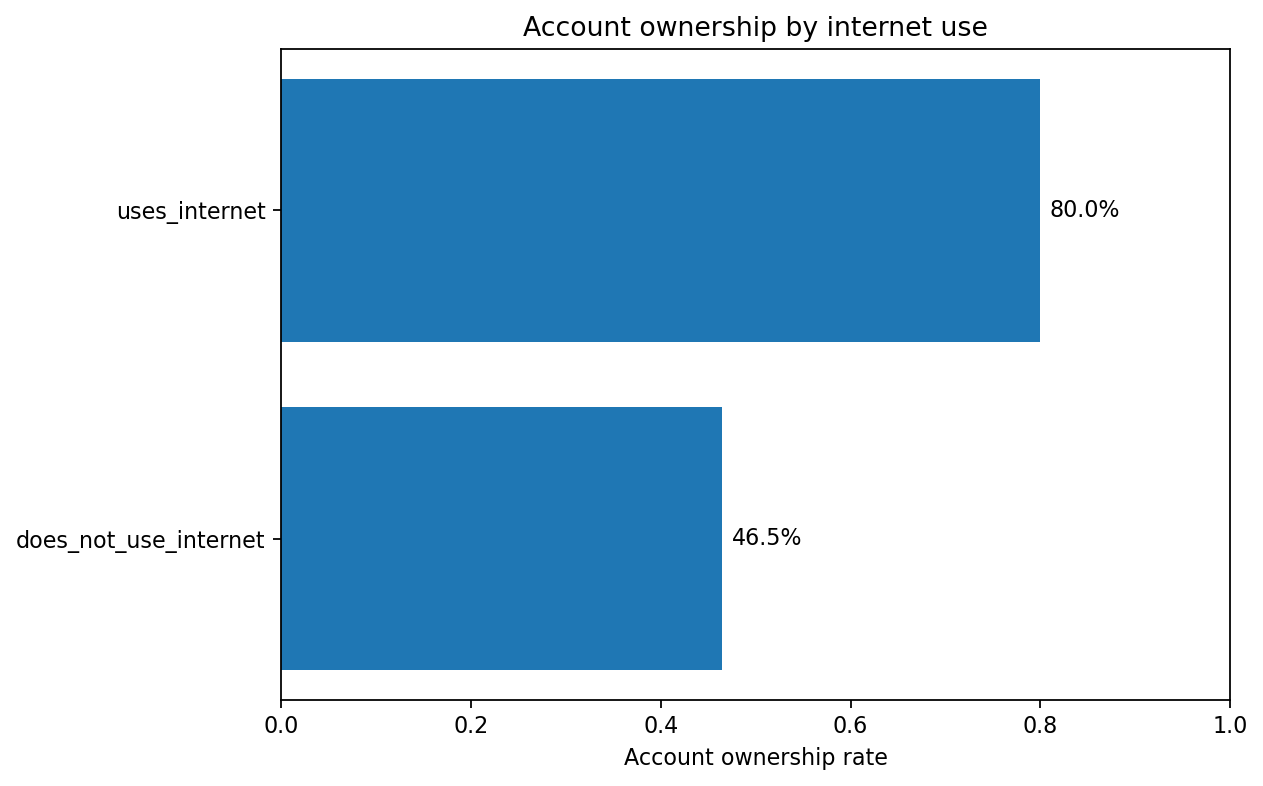

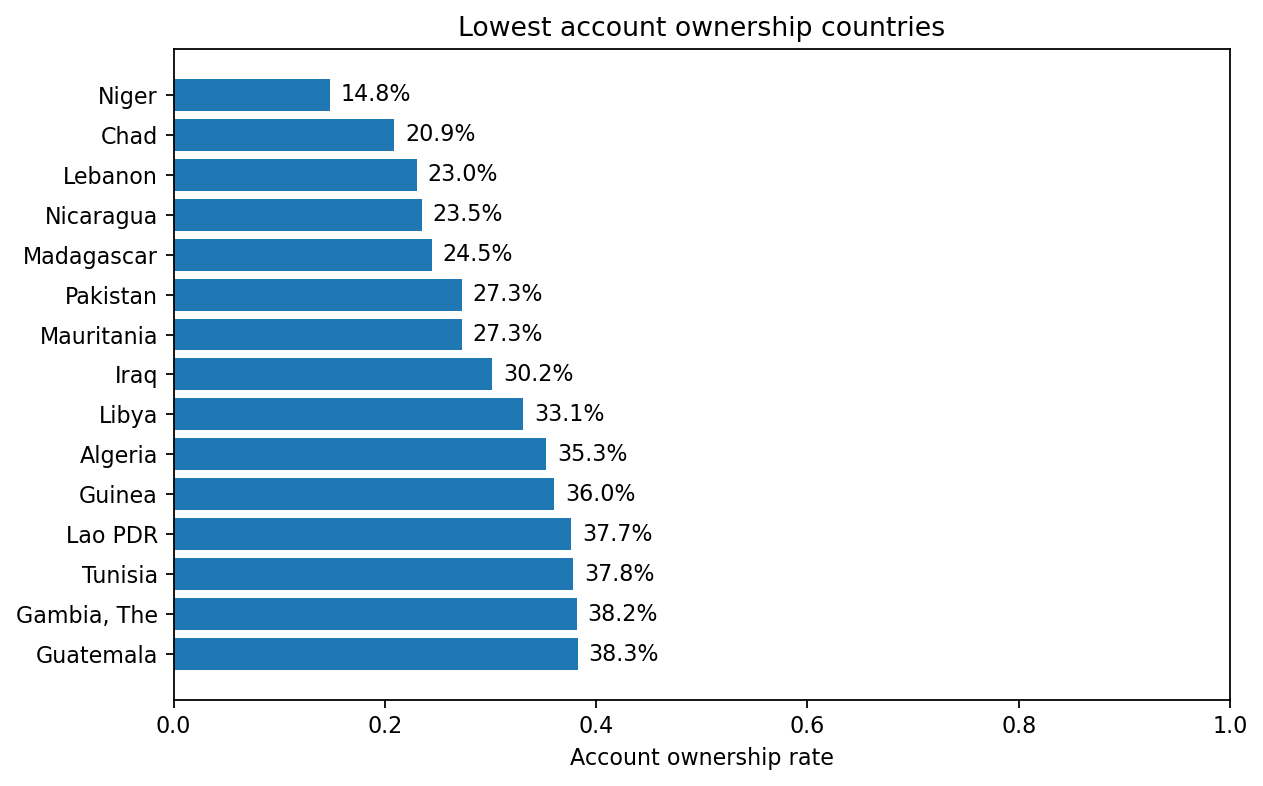

In [15]:
from IPython.display import Image, display

for name in ['account_by_education.png','account_by_internet.png','lowest_account_countries.png']:
    display(Image(filename=str(FIGURES_DIR / name)))


# EDA conclusion

The first EDA suggests that financial exclusion is not randomly distributed. Lower account ownership is associated with lower education, lower income, no internet use, rural residence, and specific lower-inclusion regions and countries.

This motivates the next project step: feature engineering and baseline modeling of account ownership.

Important caution: these are descriptive associations, not causal effects.# EDA conclusion

The first EDA suggests that financial exclusion is not randomly distributed. It is concentrated among adults with lower education, lower income, no internet use, rural residence, and in specific lower-inclusion regions and countries.

This motivates the next project step: feature engineering and baseline modeling of account ownership.

Important caution: these are descriptive associations, not causal effects.
